# Phase 4 — Machine learning and evaluation

Three classical models on the Phase 3 features: **Logistic Regression** (linear baseline), **SVM with RBF kernel** (non-linear),
**Random Forest** (non-linear, robust). Positive class = seizure.

Principles used here:
* **No leakage:** the scaler sits inside each scikit-learn `Pipeline`, so it is fitted on training data only; no feature selection is done on the test set.
* **Imbalance:** about 13 % of rows are seizures, so accuracy is misleading (predicting "no seizure" for everything scores ~87 %).
  We use `class_weight` to penalise missed seizures more, and judge models by sensitivity, specificity, F1, ROC-AUC and especially **PR-AUC**.
* **Honesty about the split:** there are no patient or recording IDs, so the best available split is a random stratified split of segments. See the limitation note in section 2.
* The test set is used **once**, for the final evaluation. No threshold tuning is done on it.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from eeg_signal_classification import evaluate as ev, train as tr
from eeg_signal_classification.utils import FEATURE_FILE, MODELS_DIR, RANDOM_SEED, RESULTS_DIR, load_structure, set_seed

set_seed(); sns.set_theme(style="whitegrid"); FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
structure = load_structure()
print("label mapping:", {"seizure": structure["seizure_label"], "non-seizure": structure["non_seizure_label"]}, "->", structure["label_status"])
print("feature layout:", structure["layout"], "| patient-independent evaluation possible:", structure["patient_independent_evaluation_possible"])
table = tr.load_feature_table(FEATURE_FILE)
X, y, row_index = tr.prepare_xy(table, structure["seizure_label"])
print("X:", X.shape, "| seizure rows:", int(y.sum()), f"({y.mean():.1%})")

label mapping: {'seizure': 1, 'non-seizure': 0} -> inferred: observed class counts match the counts reported by the dataset creator
feature layout: blocks | patient-independent evaluation possible: False
X: (11233, 450) | seizure rows: 1434 (12.8%)


## 1. Train/test split

80 % / 20 %, stratified so both sets keep the same seizure fraction, fixed seed.

In [2]:
train_idx, test_idx = tr.stratified_indices(y, test_size=0.2, seed=RANDOM_SEED)
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
pd.DataFrame({"train": [len(y_train), int(y_train.sum()), y_train.mean()], "test": [len(y_test), int(y_test.sum()), y_test.mean()]},
             index=["rows", "seizure rows", "seizure fraction"])

,train,test
rows,8986.000000,2247.000000
seizure rows,1147.000000,287.000000
seizure fraction,0.127643,0.127726


## 2. Limitation of this split (read before quoting any score)

This CSV has no patient or recording identifier. Segments cut from the same recording are highly similar, and a random split puts neighbouring
segments into both training and test sets. The scores below therefore measure **"how well does the model recognise segments similar to ones it has seen"**,
and are likely **optimistic** for new patients. They must not be presented as patient-independent performance or clinical accuracy.
Section 7 runs one exploratory check that can reveal part of this problem.

## 3. Cross-validation on the training set

5-fold stratified CV on the **training set only** gives a feel for the variability of each model before looking at the test set.

In [3]:
models = tr.build_models(RANDOM_SEED)
cv_table = tr.cross_validate_models(models, X_train, y_train, folds=5)
cv_table.to_csv(RESULTS_DIR / "cv_results.csv"); display(cv_table.round(4))

,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std
model,,,,,,,,,,
Logistic Regression,0.9695,0.0100,0.8525,0.0370,0.9068,0.0217,0.9571,0.0203,0.9933,0.0023
SVM (RBF),0.9616,0.0108,0.8875,0.0270,0.9228,0.0150,0.9852,0.0058,0.9954,0.0019
Random Forest,0.9451,0.0153,0.9757,0.0144,0.9601,0.0144,0.9912,0.0047,0.9977,0.0015


## 4. Train on the full training set and evaluate once on the test set

In [4]:
results, rows = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred, scores = model.predict(X_test), tr.get_scores(model, X_test)
    results[name] = {"y_true": y_test, "y_pred": y_pred, "scores": scores}
    rows[name] = ev.compute_metrics(y_test, y_pred, scores)
metrics = pd.DataFrame(rows).T
metrics.to_csv(RESULTS_DIR / "model_metrics.csv")
display(metrics[["accuracy", "balanced_accuracy", "precision", "recall_sensitivity", "specificity", "f1", "mcc", "roc_auc", "pr_auc", "tn", "fp", "fn", "tp"]].round(4))
print("Baseline for PR-AUC = seizure fraction in the test set:", round(float(y_test.mean()), 4))

,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,mcc,roc_auc,pr_auc,tn,fp,fn,tp
Logistic Regression,0.9733,0.9743,0.8408,0.9756,0.9730,0.9032,0.8911,0.9961,0.9746,1907.0,53.0,7.0,280.0
SVM (RBF),0.9853,0.9797,0.9178,0.9721,0.9872,0.9442,0.9362,0.9989,0.9931,1935.0,25.0,8.0,279.0
Random Forest,0.9924,0.9748,0.9891,0.9512,0.9985,0.9698,0.9657,0.9993,0.9963,1957.0,3.0,14.0,273.0


Baseline for PR-AUC = seizure fraction in the test set: 0.1277


## 5. Plots

Confusion matrices show where each model makes its mistakes (rows = true class). Sensitivity (recall of seizures) and specificity
(recall of non-seizures) are shown together because both matter: a detector that misses seizures is dangerous, one that raises constant false alarms is unusable.

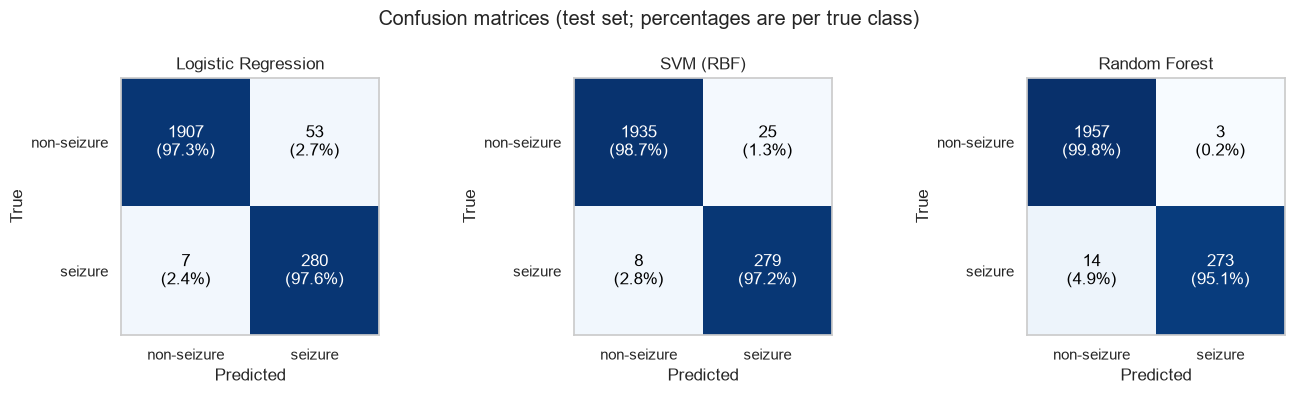

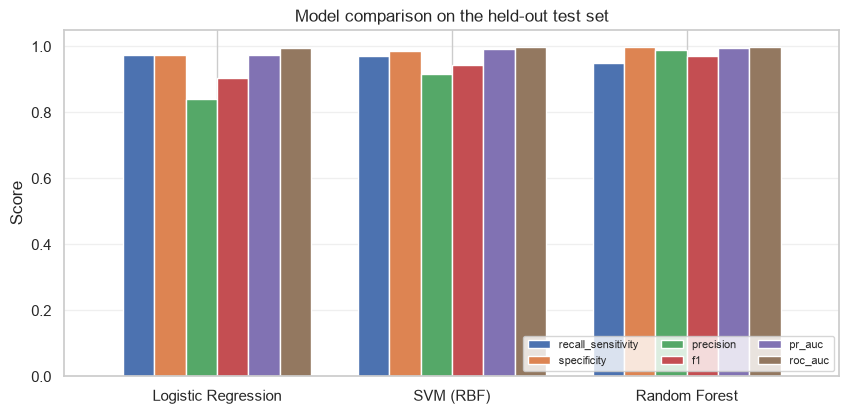

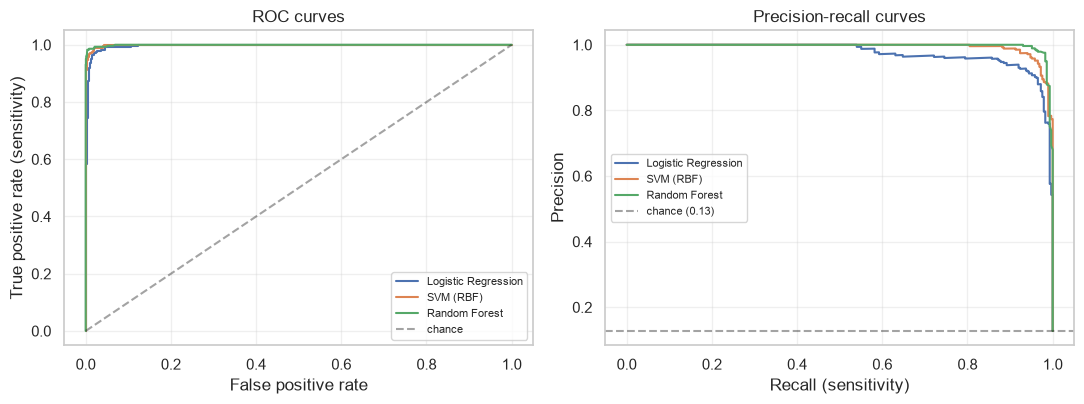

In [5]:
ev.plot_confusion_matrices(results).savefig(FIG / "04_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()
ev.plot_model_comparison(metrics).savefig(FIG / "04_model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()
ev.plot_roc_pr_curves(results).savefig(FIG / "04_roc_pr_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Save models, predictions and split

In [6]:
for name, model in models.items():
    tr.save_model(model, MODELS_DIR / (name.lower().replace(" ", "_").replace("(", "").replace(")", "") + ".joblib"))
pred = pd.DataFrame({"row_index": row_index[test_idx], "y_true": y_test})
for name, res in results.items():
    pred[f"{name} | pred"], pred[f"{name} | score"] = res["y_pred"], res["scores"]
pred.to_csv(RESULTS_DIR / "predictions.csv", index=False)
pd.DataFrame({"row_index": row_index, "split": np.where(np.isin(np.arange(len(y)), train_idx), "train", "test")}).to_csv(RESULTS_DIR / "split_indices.csv", index=False)
print("models saved:", sorted(p.name for p in MODELS_DIR.glob("*.joblib")))

models saved: ['logistic_regression.joblib', 'random_forest.joblib', 'svm_rbf.joblib']


## 7. Exploratory leakage check: ordered split

If the file keeps the original recording order, training on the first 80 % of rows and testing on the last 20 % puts the test segments in different recording
portions than the training segments. A **large drop** compared with the random split would be a warning that the random-split scores are inflated by near-duplicate
neighbours. This check is only meaningful if the labels are interleaved along the file (Phase 1, section 7) and both classes occur in both parts; otherwise it is skipped.
It is **not** a patient-wise split and does not prove generalisation either way.

In [7]:
Xo_tr, Xo_te, yo_tr, yo_te = tr.ordered_split(X, y)
if min(yo_tr.sum(), yo_te.sum()) < 10:
    ordered_table = None
    print("Skipped: fewer than 10 seizure rows in one of the ordered parts.")
else:
    rows_o = {}
    for name, model in tr.build_models(RANDOM_SEED).items():
        model.fit(Xo_tr, yo_tr)
        rows_o[name] = ev.compute_metrics(yo_te, model.predict(Xo_te), tr.get_scores(model, Xo_te))
    ordered_table = pd.DataFrame(rows_o).T
    compare = pd.DataFrame({"PR-AUC random split": metrics["pr_auc"], "PR-AUC ordered split": ordered_table["pr_auc"],
                            "recall random": metrics["recall_sensitivity"], "recall ordered": ordered_table["recall_sensitivity"]})
    display(compare.round(4)); ordered_table.to_csv(RESULTS_DIR / "ordered_split_check.csv")

,PR-AUC random split,PR-AUC ordered split,recall random,recall ordered
Logistic Regression,0.9746,0.9640,0.9756,1.0000
SVM (RBF),0.9931,0.9932,0.9721,0.9794
Random Forest,0.9963,1.0000,0.9512,1.0000


## 8. Interpretation (generated from the executed results)

In [8]:
best = metrics["pr_auc"].astype(float).idxmax()
m = metrics.loc[best]
print(f"Best model by PR-AUC on the test set: {best}")
print(f"  sensitivity {m['recall_sensitivity']:.3f}, specificity {m['specificity']:.3f}, precision {m['precision']:.3f}, F1 {m['f1']:.3f}, PR-AUC {m['pr_auc']:.3f}, ROC-AUC {m['roc_auc']:.3f}")
print(f"  it missed {int(m['fn'])} of {int(m['fn'] + m['tp'])} seizure segments and raised {int(m['fp'])} false alarms among {int(m['fp'] + m['tn'])} non-seizure segments")
print("Accuracy of always predicting 'non-seizure':", round(1 - float(y_test.mean()), 3))
spread = metrics["pr_auc"].astype(float).max() - metrics["pr_auc"].astype(float).min()
print(f"PR-AUC spread between the models: {spread:.3f}", "(models are close; the feature set matters more than the algorithm)" if spread < 0.03 else "(clear difference between the models)")
if ordered_table is not None:
    drop = float(metrics.loc[best, "pr_auc"]) - float(ordered_table.loc[best, "pr_auc"])
    print(f"PR-AUC change for {best} from random to ordered split: {drop:+.3f}", "-> large; random-split scores are probably optimistic" if drop > 0.1 else "")
print("REMINDER: segment-level random split; not patient-independent; not clinically validated.")

Best model by PR-AUC on the test set: Random Forest
  sensitivity 0.951, specificity 0.998, precision 0.989, F1 0.970, PR-AUC 0.996, ROC-AUC 0.999
  it missed 14 of 287 seizure segments and raised 3 false alarms among 1960 non-seizure segments
Accuracy of always predicting 'non-seizure': 0.872
PR-AUC spread between the models: 0.022 (models are close; the feature set matters more than the algorithm)
PR-AUC change for Random Forest from random to ordered split: -0.004 
REMINDER: segment-level random split; not patient-independent; not clinically validated.


**How to read this for your presentation:** compare models on sensitivity *and* specificity, not accuracy alone; point out the class imbalance and what PR-AUC baseline means;
state clearly that the split cannot separate patients. Deep learning (1D CNN) was left out on purpose: the classical pipeline above is the complete, verifiable baseline.